# Project - Global Pollution Analysis and Energy Recovery


# Import libraries

In [2]:
import pandas as pd  # pandas helps us work with tabular data
import numpy as np  # numpy helps us perform numerical calculations

import matplotlib.pyplot as plt  # matplotlib helps us create visualizations
import seaborn as sns  # seaborn helps us create statistical visualizations

from sklearn.preprocessing import LabelEncoder  # converts categorical values into numbers
from sklearn.preprocessing import StandardScaler  # standardizes numerical features

from sklearn.model_selection import train_test_split  # splits data into training and testing sets

from sklearn.cluster import KMeans  # K-Means clustering algorithm
from sklearn.cluster import AgglomerativeClustering  # Hierarchical clustering algorithm

from scipy.cluster.hierarchy import dendrogram  # creates dendrogram
from scipy.cluster.hierarchy import linkage  # calculates hierarchical clusters

from sklearn.metrics import silhouette_score  # evaluates clustering quality

from sklearn.linear_model import LinearRegression  # traditional regression model

from sklearn.metrics import (
    r2_score,  # calculates R²
    mean_squared_error,  # calculates MSE
    mean_absolute_error  # calculates MAE
)

import tensorflow as tf  # TensorFlow helps us build neural networks
from tensorflow.keras.models import Sequential  # creates sequential neural networks
from tensorflow.keras.layers import Dense, Dropout  # creates neural network layers
from tensorflow.keras.callbacks import EarlyStopping  # stops training when validation stops improving

# Load dataset

In [5]:
df = pd.read_csv("/Users/shyamalkar/Desktop/ML_project/06_Food_Delivery_Time_Prediction/Global_Pollution_Analysis (2).csv")  # load the CSV dataset into a DataFrame

df.head()  # display the first five rows

,Country,Year,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
0,Hungary,2005,272.70,124.27,51.95,94802.83,158.14,5.30,41.11,37078.88,12.56,42.22,20972.96
1,Singapore,2001,86.72,60.34,117.22,56283.92,498.04,6.34,36.44,33128.20,5.23,137.25,34850.41
2,Romania,2016,91.59,83.36,121.72,56256.02,489.51,49.69,9.38,18803.46,13.15,124.47,57773.15
3,Cook Islands,2018,280.61,67.16,93.58,74864.73,145.18,8.91,18.97,9182.27,0.78,67.80,21837.51
4,Djibouti,2008,179.16,127.53,121.55,76862.06,40.38,14.93,34.00,39235.12,12.84,186.52,41379.37


`Understnad the data`

In [7]:
print("Dataset Shape:", df.shape)  # display the number of rows and columns

print("\nColumn Names:")
print(df.columns)  # display all column names

print("\nData Types:")
print(df.dtypes)  # display the data type of every column

Dataset Shape: (200, 13)

Column Names:
Index(['Country', 'Year', 'Air_Pollution_Index', 'Water_Pollution_Index',
       'Soil_Pollution_Index', 'Industrial_Waste (in tons)',
       'Energy_Recovered (in GWh)', 'CO2_Emissions (in MT)',
       'Renewable_Energy (%)', 'Plastic_Waste_Produced (in tons)',
       'Energy_Consumption_Per_Capita (in MWh)', 'Population (in millions)',
       'GDP_Per_Capita (in USD)'],
      dtype='str')

Data Types:
Country                                       str
Year                                        int64
Air_Pollution_Index                       float64
Water_Pollution_Index                     float64
Soil_Pollution_Index                      float64
Industrial_Waste (in tons)                float64
Energy_Recovered (in GWh)                 float64
CO2_Emissions (in MT)                     float64
Renewable_Energy (%)                      float64
Plastic_Waste_Produced (in tons)          float64
Energy_Consumption_Per_Capita (in MWh)    float64
Pop

In [8]:
df.describe().round(2)  # display statistical summary of numerical columns

,Year,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Industrial_Waste (in tons),Energy_Recovered (in GWh),CO2_Emissions (in MT),Renewable_Energy (%),Plastic_Waste_Produced (in tons),Energy_Consumption_Per_Capita (in MWh),Population (in millions),GDP_Per_Capita (in USD)
count,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00
mean,2009.34,180.63,115.07,76.49,52891.68,260.45,24.88,27.80,24492.89,9.44,104.27,35307.60
std,5.77,67.07,47.58,39.69,27224.49,147.14,14.47,12.36,14421.36,5.58,56.91,19481.71
min,2000.00,50.30,31.13,11.15,1019.37,11.73,1.92,5.04,542.95,0.53,2.32,1298.70
25%,2004.00,134.97,74.55,40.89,31201.97,118.35,11.22,17.70,12843.88,4.58,60.96,19525.02
50%,2010.00,183.38,112.30,78.60,55299.15,273.14,25.36,29.17,24121.54,9.22,104.96,35043.32
75%,2014.00,237.42,157.48,109.21,74805.82,384.96,38.55,37.07,36516.23,14.00,150.93,51629.55
max,2019.00,297.95,199.32,149.23,99739.36,499.98,49.69,49.56,49852.28,19.98,198.82,69143.14


In [9]:
print(
    df.isnull().sum()
)  # count missing values in every column

Country                                   0
Year                                      0
Air_Pollution_Index                       0
Water_Pollution_Index                     0
Soil_Pollution_Index                      0
Industrial_Waste (in tons)                0
Energy_Recovered (in GWh)                 0
CO2_Emissions (in MT)                     0
Renewable_Energy (%)                      0
Plastic_Waste_Produced (in tons)          0
Energy_Consumption_Per_Capita (in MWh)    0
Population (in millions)                  0
GDP_Per_Capita (in USD)                   0
dtype: int64


In [10]:
df.duplicated().sum()

np.int64(0)

# Encode country and Year 

In [12]:
# The assignment specifically asks Label Encoding
country_encoder = LabelEncoder()  # create a LabelEncoder for Country

df['Country_Encoded'] = country_encoder.fit_transform(
    df['Country']
)  # convert country names into numerical values

In [13]:
# Year
year_encoder = LabelEncoder()  # create a LabelEncoder for Year

df['Year_Encoded'] = year_encoder.fit_transform(
    df['Year'].astype(str)
)  # convert year values into numerical labels

In [14]:
# Scale Pollution indices 
pollution_columns = [
    'Air_Pollution_Index',
    'Water_Pollution_Index',
    'Soil_Pollution_Index'
]  # select air, water and soil pollution features

In [15]:
pollution_scaler = StandardScaler()  # create a standard scaler

df[
    ['Air_Pollution_Scaled',
     'Water_Pollution_Scaled',
     'Soil_Pollution_Scaled']
] = pollution_scaler.fit_transform(
    df[pollution_columns]
)  # standardize the three pollution indices

In [16]:
df[
    pollution_columns +
    [
        'Air_Pollution_Scaled',
        'Water_Pollution_Scaled',
        'Soil_Pollution_Scaled'
    ]
].head()

,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Air_Pollution_Scaled,Water_Pollution_Scaled,Soil_Pollution_Scaled
0,272.70,124.27,51.95,1.376167,0.193880,-0.619764
1,86.72,60.34,117.22,-1.403578,-1.153098,1.028744
2,91.59,83.36,121.72,-1.330788,-0.668076,1.142400
3,280.61,67.16,93.58,1.494394,-1.009403,0.431675
4,179.16,127.53,121.55,-0.021926,0.262567,1.138106


# Energy consumption Per capita

In [17]:
df[
    ['Population (in millions)',
     'Energy_Consumption_Per_Capita (in MWh)']
].head()  # check the existing energy consumption feature

,Population (in millions),Energy_Consumption_Per_Capita (in MWh)
0,42.22,12.56
1,137.25,5.23
2,124.47,13.15
3,67.80,0.78
4,186.52,12.84


# Create Overall Pollution Score

In [19]:
# This will help us analyze overall pollution
df['Overall_Pollution_Index'] = df[
    pollution_columns
].mean(
    axis=1
)  # calculate average air, water and soil pollution

In [20]:
# Check 

df[
    [
        'Air_Pollution_Index',
        'Water_Pollution_Index',
        'Soil_Pollution_Index',
        'Overall_Pollution_Index'
    ]
].head()

,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Overall_Pollution_Index
0,272.70,124.27,51.95,149.640000
1,86.72,60.34,117.22,88.093333
2,91.59,83.36,121.72,98.890000
3,280.61,67.16,93.58,147.116667
4,179.16,127.53,121.55,142.746667


# Analyze Yearly Pollution Trends

In [21]:
yearly_analysis = df.groupby(
    'Year'
).agg(
    Average_Air_Pollution=(
        'Air_Pollution_Index',
        'mean'
    ),

    Average_Water_Pollution=(
        'Water_Pollution_Index',
        'mean'
    ),

    Average_Soil_Pollution=(
        'Soil_Pollution_Index',
        'mean'
    ),

    Average_Energy_Recovered=(
        'Energy_Recovered (in GWh)',
        'mean'
    )
).reset_index()  # calculate yearly environmental and energy averages

yearly_analysis

,Year,Average_Air_Pollution,Average_Water_Pollution,Average_Soil_Pollution,Average_Energy_Recovered
0,2000,197.796000,118.513000,69.283000,296.889000
1,2001,137.964444,83.933333,71.340000,288.877778
2,2002,174.661538,123.617692,75.344615,259.750769
3,2003,203.103000,133.080000,100.687000,208.139000
4,2004,171.120909,120.719091,69.959091,186.458182
5,2005,179.756000,108.245333,72.922000,240.748667
6,2006,197.326667,115.016667,100.613333,197.411667
7,2007,174.349091,107.464545,55.718182,242.578182
8,2008,194.782857,102.114286,75.508571,289.600000
9,2009,200.440000,99.040000,68.994000,224.424000


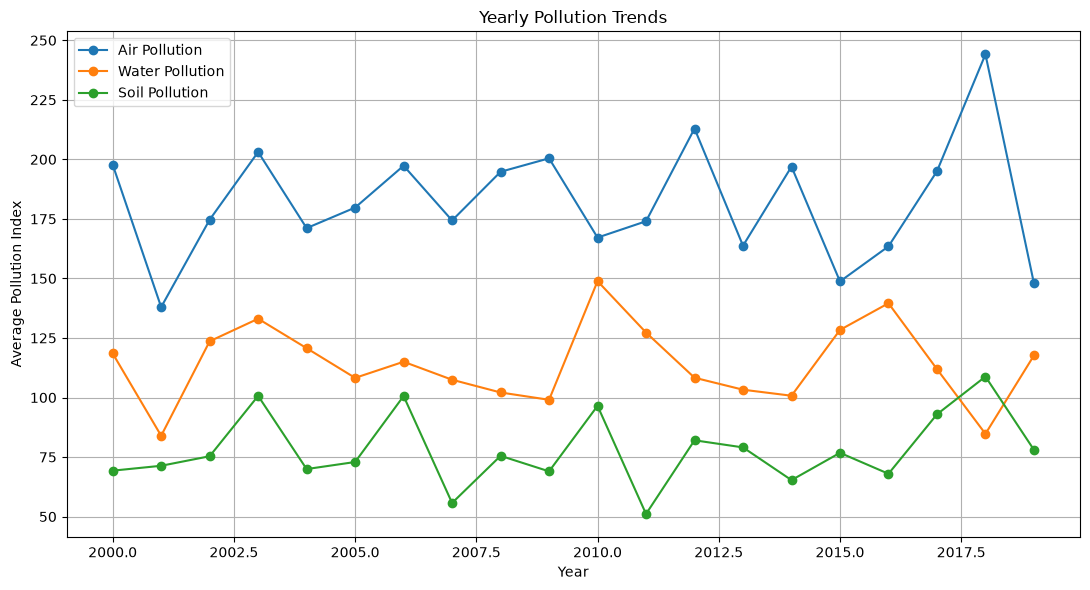

In [22]:
plt.figure(figsize=(11, 6))

plt.plot(
    yearly_analysis['Year'],
    yearly_analysis['Average_Air_Pollution'],
    marker='o',
    label='Air Pollution'
)  # plot yearly air pollution

plt.plot(
    yearly_analysis['Year'],
    yearly_analysis['Average_Water_Pollution'],
    marker='o',
    label='Water Pollution'
)  # plot yearly water pollution

plt.plot(
    yearly_analysis['Year'],
    yearly_analysis['Average_Soil_Pollution'],
    marker='o',
    label='Soil Pollution'
)  # plot yearly soil pollution

plt.xlabel('Year')
plt.ylabel('Average Pollution Index')
plt.title('Yearly Pollution Trends')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Phase 2 - K-Means Clustering 

In [23]:
clustering_features = [
    'Air_Pollution_Index',
    'Water_Pollution_Index',
    'Soil_Pollution_Index',
    'Industrial_Waste (in tons)',
    'Energy_Recovered (in GWh)',
    'CO2_Emissions (in MT)',
    'Renewable_Energy (%)',
    'Energy_Consumption_Per_Capita (in MWh)',
    'Plastic_Waste_Produced (in tons)',
    'Population (in millions)',
    'GDP_Per_Capita (in USD)'
]  # select environmental and energy features

In [24]:
X_cluster = df[
    clustering_features
]  # create the clustering dataset

In [25]:
cluster_scaler = StandardScaler()  # create a scaler for clustering

X_cluster_scaled = cluster_scaler.fit_transform(
    X_cluster
)  # standardize all clustering features

# Elbow Method 

In [26]:
inertia = []  # store K-Means inertia values

k_values = range(2, 11)  # test cluster numbers from 2 to 10

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )  # create K-Means model

    kmeans.fit(
        X_cluster_scaled
    )  # train K-Means

    inertia.append(
        kmeans.inertia_
    )  # store inertia

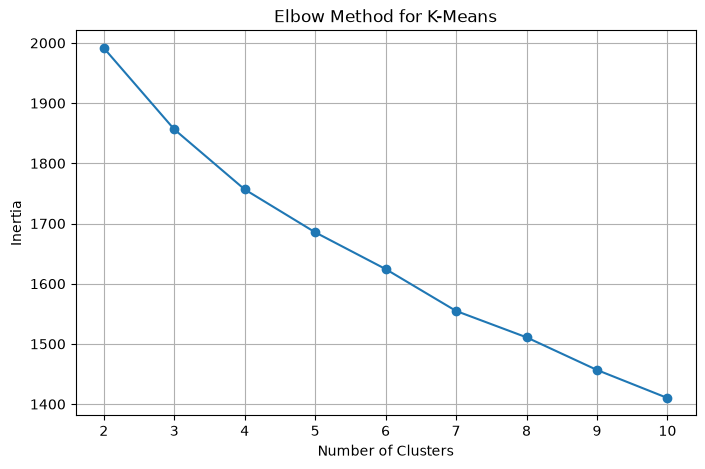

In [28]:
# Plot 

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker='o'
)  # plot the elbow curve

plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for K-Means')
plt.grid(True)
plt.show()

# Train Final K-means

In [31]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)  # create the final K-Means model

In [32]:
df['KMeans_Cluster'] = kmeans.fit_predict(
    X_cluster_scaled
)  # assign every observation to a K-Means cluster

In [33]:
# Check 

df['KMeans_Cluster'].value_counts()

KMeans_Cluster
0    70
2    66
1    64
Name: count, dtype: int64

In [34]:
# K-Means Evaluation 
kmeans_silhouette = silhouette_score(
    X_cluster_scaled,
    df['KMeans_Cluster']
)  # calculate K-Means silhouette score

print(
    "K-Means Silhouette Score:",
    round(kmeans_silhouette, 4)
)

K-Means Silhouette Score: 0.0803


In [35]:
# Analyze K-Means Clusters
kmeans_analysis = df.groupby(
    'KMeans_Cluster'
)[
    [
        'Air_Pollution_Index',
        'Water_Pollution_Index',
        'Soil_Pollution_Index',
        'Energy_Recovered (in GWh)',
        'CO2_Emissions (in MT)',
        'Energy_Consumption_Per_Capita (in MWh)'
    ]
].mean().round(2)  # calculate average characteristics of each cluster

kmeans_analysis

,Air_Pollution_Index,Water_Pollution_Index,Soil_Pollution_Index,Energy_Recovered (in GWh),CO2_Emissions (in MT),Energy_Consumption_Per_Capita (in MWh)
KMeans_Cluster,,,,,,
0,166.34,135.97,87.09,210.38,27.71,9.36
1,211.90,91.76,96.27,329.91,24.52,8.79
2,165.46,115.50,46.07,246.20,22.22,10.14


# Visualize K-Means Cluster 

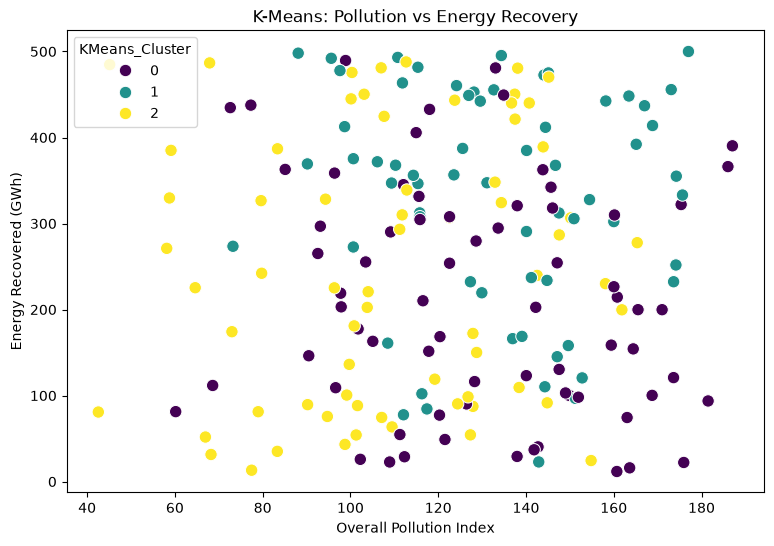

In [36]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Overall_Pollution_Index',
    y='Energy_Recovered (in GWh)',
    hue='KMeans_Cluster',
    palette='viridis',
    s=80
)  # visualize pollution and energy recovery clusters

plt.title('K-Means: Pollution vs Energy Recovery')
plt.xlabel('Overall Pollution Index')
plt.ylabel('Energy Recovered (GWh)')
plt.show()

# Phase 2 - HIERARCHICAL CLUSTERING

In [38]:
# create hierarchical linkage 
linkage_matrix = linkage(
    X_cluster_scaled,
    method='ward'
)  # calculate hierarchical cluster relationships

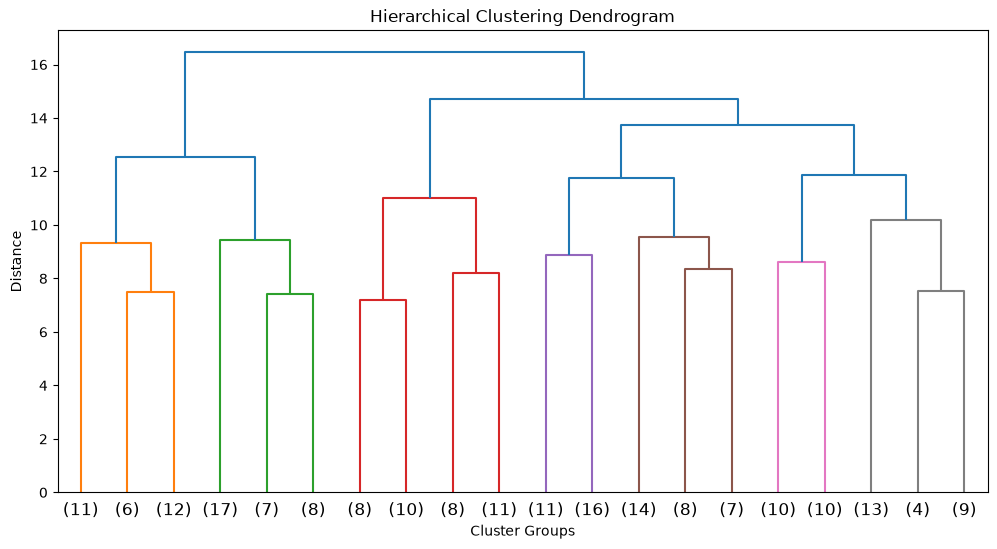

In [40]:
# Dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=20
)  # create the hierarchical clustering dendrogram

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Cluster Groups')
plt.ylabel('Distance')
plt.show()

In [42]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)  # create the hierarchical clustering model

# Train Hierarchical Clustering

In [43]:
df['Hierarchical_Cluster'] = hierarchical_model.fit_predict(
    X_cluster_scaled
)  # assign each observation to a hierarchical cluster

In [45]:
# Evaluate Hierarchical Clustering
hierarchical_silhouette = silhouette_score(
    X_cluster_scaled,
    df['Hierarchical_Cluster']
)  # calculate hierarchical silhouette score

print(
    "Hierarchical Silhouette Score:",
    round(hierarchical_silhouette, 4)
)

Hierarchical Silhouette Score: 0.0487


In [46]:
# Compare 

clustering_results = pd.DataFrame({
    'Method': [
        'K-Means',
        'Hierarchical'
    ],

    'Silhouette_Score': [
        kmeans_silhouette,
        hierarchical_silhouette
    ]
}).round(4)  # create clustering comparison table

clustering_results

,Method,Silhouette_Score
0,K-Means,0.0803
1,Hierarchical,0.0487


In [47]:
# Hierarchical Clustering Analysis 
hierarchical_analysis = df.groupby(
    'Hierarchical_Cluster'
)[
    [
        'Overall_Pollution_Index',
        'Energy_Recovered (in GWh)',
        'CO2_Emissions (in MT)',
        'Energy_Consumption_Per_Capita (in MWh)'
    ]
].mean().round(2)  # summarize each hierarchical cluster

hierarchical_analysis

,Overall_Pollution_Index,Energy_Recovered (in GWh),CO2_Emissions (in MT),Energy_Consumption_Per_Capita (in MWh)
Hierarchical_Cluster,,,,
0,132.26,285.02,21.56,10.96
1,116.61,232.65,24.54,6.34
2,113.73,238.53,34.57,10.33


In [48]:
# Compare K-Means and Hierarchical cluster 
cluster_comparison = df[
    [
        'Country',
        'Year',
        'KMeans_Cluster',
        'Hierarchical_Cluster',
        'Overall_Pollution_Index',
        'Energy_Recovered (in GWh)'
    ]
].head(20)  # compare cluster assignments

cluster_comparison

,Country,Year,KMeans_Cluster,Hierarchical_Cluster,Overall_Pollution_Index,Energy_Recovered (in GWh)
0,Hungary,2005,1,0,149.640000,158.14
1,Singapore,2001,1,0,88.093333,498.04
2,Romania,2016,0,2,98.890000,489.51
3,Cook Islands,2018,1,1,147.116667,145.18
4,Djibouti,2008,0,0,142.746667,40.38
5,Croatia,2009,2,2,99.726667,136.26
6,Congo,2008,2,1,161.853333,199.71
7,Central African Republic,2006,1,0,177.016667,499.98
8,Swaziland,2007,1,0,134.383333,495.28
9,Sri Lanka,2002,1,0,144.096667,472.63


# Neural Network for Energy Recovery 
`Now we build the main prediction model `

In [50]:
nn_features = [
    'Air_Pollution_Index',
    'Water_Pollution_Index',
    'Soil_Pollution_Index',
    'Industrial_Waste (in tons)',
    'CO2_Emissions (in MT)',
    'Renewable_Energy (%)',
    'Plastic_Waste_Produced (in tons)',
    'Energy_Consumption_Per_Capita (in MWh)',
    'Population (in millions)',
    'GDP_Per_Capita (in USD)',
    'Year_Encoded'
]  # select pollution, energy and economic features

In [51]:
X = df[
    nn_features
]  # create neural network input features

y = df[
    'Energy_Recovered (in GWh)'
]  # create energy recovery target

# Train - Test Split

In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)  # split the data into training and testing sets

# Scale Neural Network Features 

In [53]:
nn_scaler = StandardScaler()  # create standard scaler

X_train_scaled = nn_scaler.fit_transform(
    X_train
)  # fit scaler using training data

X_test_scaled = nn_scaler.transform(
    X_test
)  # transform test data using training scaler

# Build FeedFordard Neural Network 

In [54]:
model = Sequential([

    Dense(
        64,
        activation='relu',
        input_shape=(X_train_scaled.shape[1],)
    ),  # first hidden layer with 64 neurons

    Dense(
        32,
        activation='relu'
    ),  # second hidden layer with 32 neurons

    Dropout(
        0.2
    ),  # randomly deactivate 20% of neurons to reduce overfitting

    Dense(
        16,
        activation='relu'
    ),  # third hidden layer with 16 neurons

    Dense(
        1
    )  # output layer for regression
])

/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Compile the neuralnetwork 


In [55]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),  # use Adam optimizer with learning rate 0.001

    loss='mse',  # use Mean Squared Error as the regression loss

    metrics=['mae']  # monitor Mean Absolute Error during training
)

# Early Stoping 

In [56]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)  # stop training when validation loss stops improving

# Train Neural network 

In [57]:
history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=200,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)  # train the neural network

Epoch 1/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 94817.7969 - mae: 272.3910 - val_loss: 77172.1016 - val_mae: 238.4478
Epoch 2/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 94626.6562 - mae: 272.0521 - val_loss: 77029.1094 - val_mae: 238.1311
Epoch 3/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 94447.0000 - mae: 271.7200 - val_loss: 76867.1406 - val_mae: 237.7779
Epoch 4/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 94200.3906 - mae: 271.2893 - val_loss: 76664.3906 - val_mae: 237.3414
Epoch 5/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 93954.6797 - mae: 270.8344 - val_loss: 76403.9375 - val_mae: 236.7805
Epoch 6/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 93557.8516 - mae: 270.1109 - val_loss: 76065.4297 - val_mae: 236.0463
Epoch 7/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 93084.5781 - mae: 269.2367 - val_loss: 75615.1562 - val_mae: 235.0667
Epoch 8/200
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 92352.1172 - mae: 267.9121 - val_loss: 75018.0391 - v

# Predict Energy recovery 

In [59]:
y_pred_nn = model.predict(
    X_test_scaled
).ravel()  # predict energy recovery for test data

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


# Evaluate Neural network 

In [60]:
nn_r2 = r2_score(
    y_test,
    y_pred_nn
)  # calculate R²

nn_mse = mean_squared_error(
    y_test,
    y_pred_nn
)  # calculate MSE

nn_mae = mean_absolute_error(
    y_test,
    y_pred_nn
)  # calculate MAE

print("Neural Network Results")
print("----------------------")
print("R²  :", round(nn_r2, 4))
print("MSE :", round(nn_mse, 2))
print("MAE :", round(nn_mae, 2))

Neural Network Results
----------------------
R²  : -0.2742
MSE : 30813.43
MAE : 156.63


# Actual vs Predicted energy Recovery 

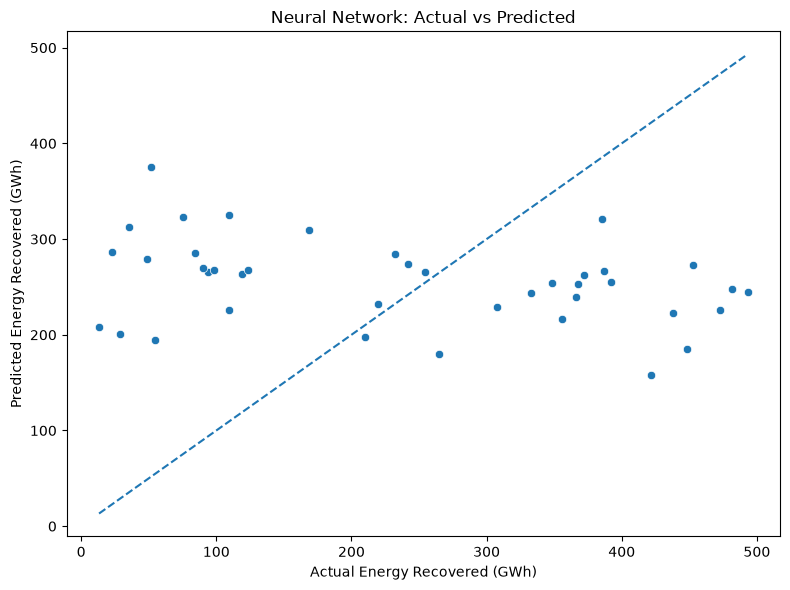

In [61]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_nn
)  # plot actual and predicted energy values

plt.xlabel('Actual Energy Recovered (GWh)')
plt.ylabel('Predicted Energy Recovered (GWh)')
plt.title('Neural Network: Actual vs Predicted')

min_value = min(
    y_test.min(),
    y_pred_nn.min()
)  # find minimum value

max_value = max(
    y_test.max(),
    y_pred_nn.max()
)  # find maximum value

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)  # add perfect prediction reference line

plt.tight_layout()
plt.show()

# Neural network Training Performance 

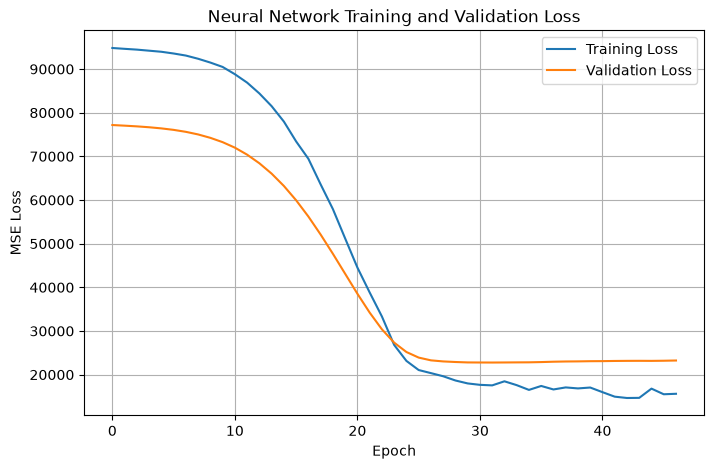

In [62]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)  # plot training loss

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)  # plot validation loss

plt.title('Neural Network Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.show()

# Tune Neural Network 

In [63]:
def build_nn(
    neurons=64,
    learning_rate=0.001
):

    model = Sequential([

        Dense(
            neurons,
            activation='relu',
            input_shape=(X_train_scaled.shape[1],)
        ),  # first hidden layer

        Dense(
            neurons // 2,
            activation='relu'
        ),  # second hidden layer

        Dense(
            1
        )  # regression output
    ])

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )  # create optimizer

    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']
    )  # compile the neural network

    return model

In [64]:
# Try a tuned configuration:
tuned_model = build_nn(
    neurons=128,
    learning_rate=0.0005
)  # create a larger network with a lower learning rate

/Users/shyamalkar/Desktop/ML_project/MLvenv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [65]:
# Train 
tuned_history = tuned_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=200,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=0
)  # train the tuned model

In [66]:
# Predict 
y_pred_tuned = tuned_model.predict(
    X_test_scaled,
    verbose=0
).ravel()  # generate predictions from the tuned model

In [67]:
# Evaluate 
tuned_r2 = r2_score(
    y_test,
    y_pred_tuned
)  # calculate tuned R²

tuned_mse = mean_squared_error(
    y_test,
    y_pred_tuned
)  # calculate tuned MSE

tuned_mae = mean_absolute_error(
    y_test,
    y_pred_tuned
)  # calculate tuned MAE

print("Tuned Neural Network")
print("--------------------")
print("R²  :", round(tuned_r2, 4))
print("MSE :", round(tuned_mse, 2))
print("MAE :", round(tuned_mae, 2))

Tuned Neural Network
--------------------
R²  : -0.2118
MSE : 29304.98
MAE : 152.14


# Phase 3 - Linear regression Comparison

`Build Linear regression`

In [68]:
linear_model = LinearRegression()  # create Linear Regression model

In [69]:
linear_model.fit(
    X_train_scaled,
    y_train
)  # train Linear Regression

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ -9.54, 4.38, 3.11,...,-18.85, 8.82, 19.05]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,265.7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](11,)","[15.7 ,14.9 ,14.12,...,11.41, 9.95, 9.62]"


In [72]:
# Predict 

y_pred_linear = linear_model.predict(
    X_test_scaled
)  # predict energy recovery

# Evaluate Linear regression 


In [73]:
linear_r2 = r2_score(
    y_test,
    y_pred_linear
)  # calculate Linear Regression R²

linear_mse = mean_squared_error(
    y_test,
    y_pred_linear
)  # calculate Linear Regression MSE

linear_mae = mean_absolute_error(
    y_test,
    y_pred_linear
)  # calculate Linear Regression MAE

print("Linear Regression Results")
print("-------------------------")
print("R²  :", round(linear_r2, 4))
print("MSE :", round(linear_mse, 2))
print("MAE :", round(linear_mae, 2))

Linear Regression Results
-------------------------
R²  : -0.1461
MSE : 27715.08
MAE : 145.98


# Neural network vs Linear regression

In [74]:
model_comparison = pd.DataFrame({

    'Model': [
        'Linear Regression',
        'Neural Network',
        'Tuned Neural Network'
    ],

    'R2': [
        linear_r2,
        nn_r2,
        tuned_r2
    ],

    'MSE': [
        linear_mse,
        nn_mse,
        tuned_mse
    ],

    'MAE': [
        linear_mae,
        nn_mae,
        tuned_mae
    ]

}).round(4)  # create regression model comparison table

model_comparison

,Model,R2,MSE,MAE
0,Linear Regression,-0.1461,27715.0790,145.9793
1,Neural Network,-0.2742,30813.4339,156.6289
2,Tuned Neural Network,-0.2118,29304.9843,152.1416


# Visualization Model Comparison

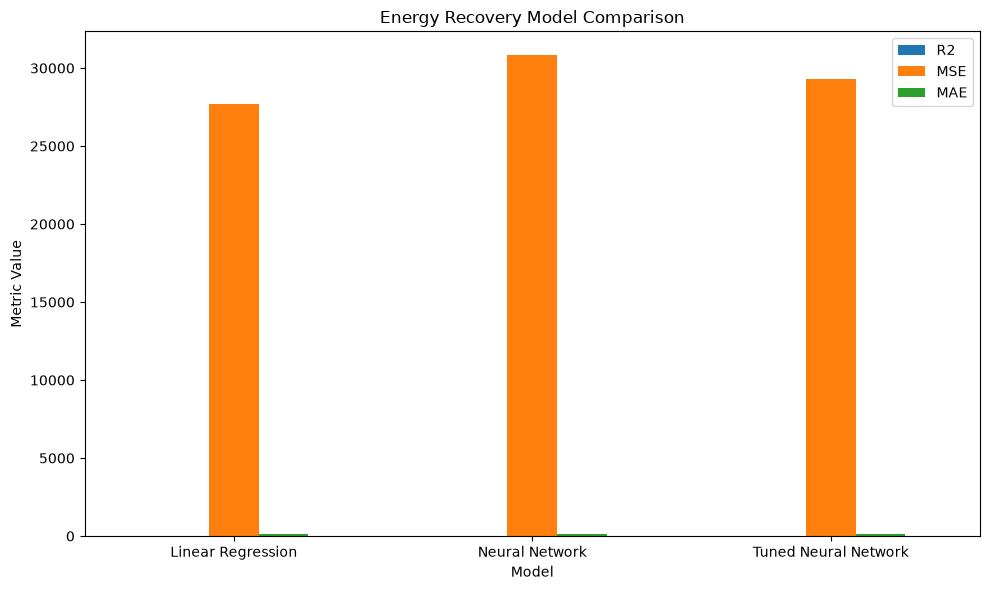

In [75]:
model_comparison.set_index(
    'Model'
)[
    ['R2', 'MSE', 'MAE']
].plot(
    kind='bar',
    figsize=(10, 6)
)  # compare regression model performance

plt.title('Energy Recovery Model Comparison')
plt.ylabel('Metric Value')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Pollution vs Energy Recovery 

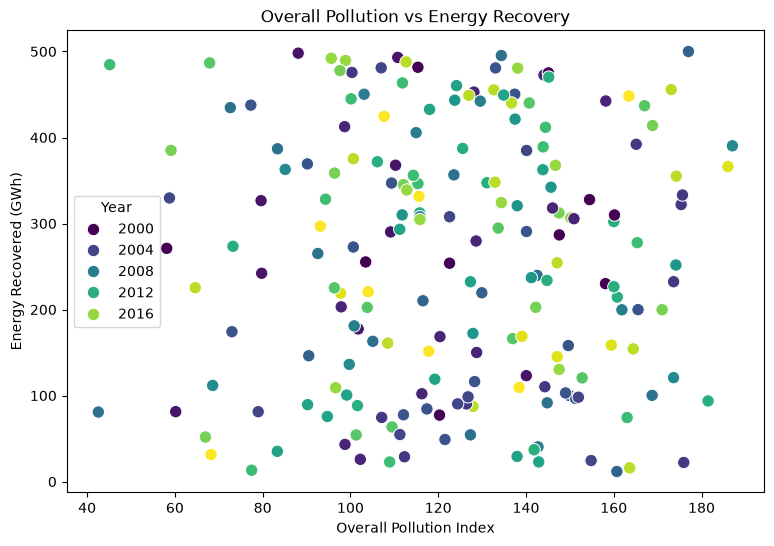

In [76]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Overall_Pollution_Index',
    y='Energy_Recovered (in GWh)',
    hue='Year',
    palette='viridis',
    s=80
)  # visualize pollution and energy recovery relationship

plt.title('Overall Pollution vs Energy Recovery')
plt.xlabel('Overall Pollution Index')
plt.ylabel('Energy Recovered (GWh)')
plt.show()

# Industrial Waste vs Energy Recorvery 

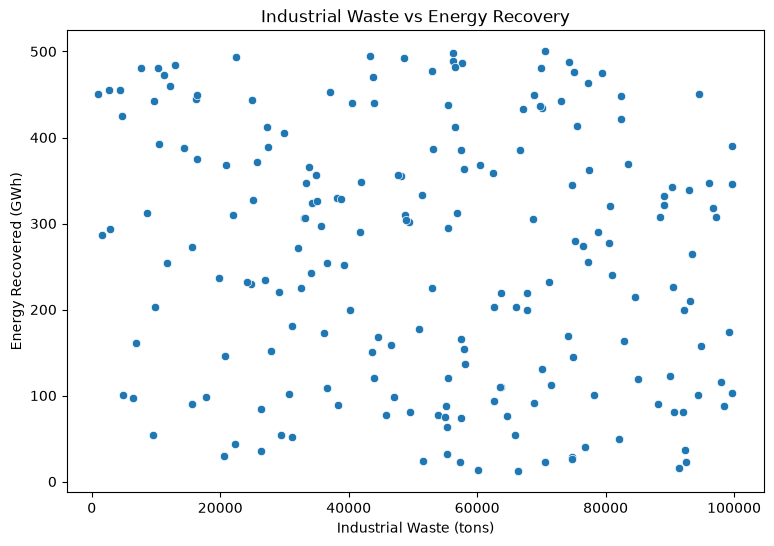

In [77]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Industrial_Waste (in tons)',
    y='Energy_Recovered (in GWh)'
)  # visualize industrial waste and energy recovery

plt.title('Industrial Waste vs Energy Recovery')
plt.xlabel('Industrial Waste (tons)')
plt.ylabel('Energy Recovered (GWh)')
plt.show()

# Correlation with Energy Recovery 

In [78]:
energy_correlation = df[
    [
        'Air_Pollution_Index',
        'Water_Pollution_Index',
        'Soil_Pollution_Index',
        'Industrial_Waste (in tons)',
        'CO2_Emissions (in MT)',
        'Renewable_Energy (%)',
        'Plastic_Waste_Produced (in tons)',
        'Energy_Consumption_Per_Capita (in MWh)',
        'Population (in millions)',
        'GDP_Per_Capita (in USD)',
        'Energy_Recovered (in GWh)'
    ]
].corr()['Energy_Recovered (in GWh)'].sort_values(
    ascending=False
)  # calculate correlation of features with energy recovery

energy_correlation

Energy_Recovered (in GWh)                 1.000000
Soil_Pollution_Index                      0.064076
Renewable_Energy (%)                      0.043533
CO2_Emissions (in MT)                     0.024758
GDP_Per_Capita (in USD)                   0.004535
Air_Pollution_Index                       0.002997
Energy_Consumption_Per_Capita (in MWh)   -0.030284
Water_Pollution_Index                    -0.041828
Plastic_Waste_Produced (in tons)         -0.072946
Population (in millions)                 -0.075100
Industrial_Waste (in tons)               -0.161309
Name: Energy_Recovered (in GWh), dtype: float64

# Final Clustering + Prediction summary 

In [79]:
print("===== CLUSTERING RESULTS =====")

print(
    "K-Means Silhouette:",
    round(kmeans_silhouette, 4)
)

print(
    "Hierarchical Silhouette:",
    round(hierarchical_silhouette, 4)
)

print("\n===== REGRESSION RESULTS =====")

print(
    "Linear Regression R²:",
    round(linear_r2, 4)
)

print(
    "Neural Network R²:",
    round(nn_r2, 4)
)

print(
    "Tuned Neural Network R²:",
    round(tuned_r2, 4)
)

===== CLUSTERING RESULTS =====
K-Means Silhouette: 0.0803
Hierarchical Silhouette: 0.0487

===== REGRESSION RESULTS =====
Linear Regression R²: -0.1461
Neural Network R²: -0.2742
Tuned Neural Network R²: -0.2118


# Summary 


Global Pollution Analysis — Final Report

This project analyzed environmental and energy characteristics across countries using K-Means and Hierarchical Clustering and predicted energy recovery using neural networks. The preprocessing stage included missing-value handling, categorical encoding, pollution-index scaling, and feature engineering. K-Means clustering was optimized using the Elbow Method, while Hierarchical Clustering was analyzed using a dendrogram. Silhouette scores were used to compare the clustering quality. A feedforward neural network was developed to predict Energy Recovered in GWh and evaluated using R², MSE, and MAE. Linear Regression was used as a traditional baseline for comparison. The clustering results can identify countries with similar pollution and energy characteristics, while the neural network can help estimate energy recovery from environmental factors. These insights can support targeted pollution reduction, waste-to-energy development, renewable-energy adoption, and country-specific environmental planning.